<a href="https://colab.research.google.com/github/aanyasingh2905-lab/college-faq-chatbot/blob/main/Fake_News_Detection_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake News Detection using Machine Learning
**Fourth Year Lab Mini Project**

**Goal:** Classify a news article as **REAL** or **FAKE** from its text.



## 1. Import libraries

In [1]:
import re, time, os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset
We first try downloading from Kaggle using `kagglehub`. If that fails, upload `Fake.csv` and `True.csv`
(download them manually from Kaggle: *clmentbisaillon/fake-and-real-news-dataset*).

In [2]:
def load_data():
    try:
        import kagglehub
    except ImportError:
        os.system("pip install -q kagglehub")
        import kagglehub
    try:
        path = kagglehub.dataset_download("clmentbisaillon/fake-and-real-news-dataset")
        fake = pd.read_csv(os.path.join(path, "Fake.csv"))
        true = pd.read_csv(os.path.join(path, "True.csv"))
        print("Loaded from Kaggle.")
    except Exception as e:
        print("Kaggle download failed:", e)
        print("Please upload Fake.csv and True.csv now...")
        from google.colab import files
        files.upload()
        fake = pd.read_csv("Fake.csv")
        true = pd.read_csv("True.csv")
    return fake, true

fake_df, true_df = load_data()
fake_df["label"] = 0   # 0 = FAKE
true_df["label"] = 1   # 1 = REAL
df = pd.concat([fake_df, true_df], ignore_index=True)
print("Shape:", df.shape)
df.head()

100%|██████████| 41.0M/41.0M [00:00<00:00, 69.1MB/s]

Extracting files...


Loaded from Kaggle.
Shape: (44898, 5)


,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


## 3. Exploratory data analysis

title      0
text       0
subject    0
date       0
label      0
dtype: int64

Duplicates: 5793


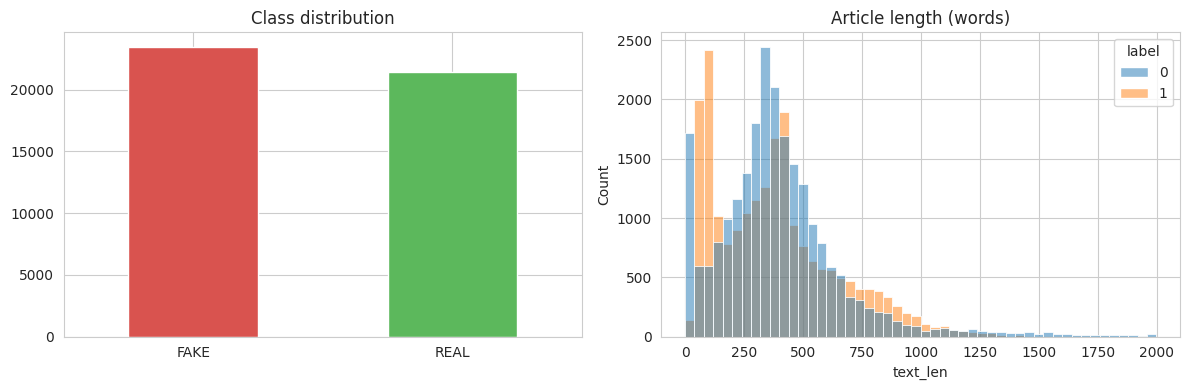

In [3]:
print(df.isnull().sum())
print("\nDuplicates:", df.duplicated(subset=["title", "text"]).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["label"].map({0: "FAKE", 1: "REAL"}).value_counts().plot(kind="bar", ax=ax[0], color=["#d9534f", "#5cb85c"])
ax[0].set_title("Class distribution"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)

df["text_len"] = df["text"].fillna("").str.split().str.len()
sns.histplot(data=df[df.text_len < 2000], x="text_len", hue="label", bins=50, ax=ax[1])
ax[1].set_title("Article length (words)")
plt.tight_layout(); plt.show()

## 4. Preprocessing
Steps: remove duplicates and empty rows -> combine title + text -> remove source giveaways
(like *"WASHINGTON (Reuters) -"* which appears only in real articles and would make the task artificially easy)
-> lowercase -> remove URLs, punctuation, numbers and extra spaces.

Stop-word removal and n-grams are handled by the TF-IDF vectorizer.

In [4]:
df = df.drop_duplicates(subset=["title", "text"]).dropna(subset=["title", "text"])
df = df[df["text"].str.strip() != ""].reset_index(drop=True)

def clean_text(t):
    t = t.lower()
    t = re.sub(r"^.{0,60}?\(reuters\)\s*-?\s*", " ", t)   # source leakage in real news
    t = re.sub(r"reuters", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)           # URLs
    t = re.sub(r"[^a-z\s]", " ", t)                           # punctuation & digits
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["content"] = (df["title"] + " " + df["text"]).apply(clean_text)

# OPTIONAL: set a number (e.g. 10000) to use a smaller sample for faster training
SAMPLE_SIZE = None
if SAMPLE_SIZE:
    df = df.sample(SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)

print("Final dataset size:", len(df))
df[["content", "label"]].head()

Final dataset size: 38658


,content,label
0,donald trump sends out embarrassing new year s...,0
1,drunk bragging trump staffer started russian c...,0
2,sheriff david clarke becomes an internet joke ...,0
3,trump is so obsessed he even has obama s name ...,0
4,pope francis just called out donald trump duri...,0


## 5. Train-test split and TF-IDF feature extraction

In [5]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["content"], df["label"], test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)

tfidf = TfidfVectorizer(stop_words="english", max_df=0.7, min_df=5,
                        max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)   # fit ONLY on training data
X_test = tfidf.transform(X_test_txt)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (30926, 50000) | Test: (7732, 50000)


## 6. Train and compare multiple algorithms
| Algorithm | Idea |
|---|---|
| Logistic Regression | Linear model giving class probabilities |
| Multinomial Naive Bayes | Probabilistic model based on word counts, very fast |
| Linear SVM | Finds the best separating hyperplane in high dimensions |
| Passive Aggressive | Online linear learner, popular for fake news |
| Decision Tree | Rule-based tree, easy to interpret |
| Random Forest | Ensemble of many decision trees |

In [6]:
models = {
    "Logistic Regression":   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Naive Bayes":           MultinomialNB(),
    "Linear SVM":            LinearSVC(random_state=RANDOM_STATE),
    "Passive Aggressive":    SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1", eta0=1.0, max_iter=50, random_state=RANDOM_STATE),
    "Decision Tree":         DecisionTreeClassifier(max_depth=30, random_state=RANDOM_STATE),
    "Random Forest":         RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
}

results, trained, preds = [], {}, {}
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    y_pred = model.predict(X_test)
    trained[name], preds[name] = model, y_pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Train time (s)": round(elapsed, 2),
    })
    print(f"{name:22s} done  acc={results[-1]['Accuracy']:.4f}  time={elapsed:.1f}s")

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
results_df.style.format({c: "{:.4f}" for c in ["Accuracy", "Precision", "Recall", "F1-score"]})

Logistic Regression    done  acc=0.9836  time=1.4s
Naive Bayes            done  acc=0.9531  time=0.1s
Linear SVM             done  acc=0.9908  time=0.7s
Passive Aggressive     done  acc=0.9915  time=0.4s
Decision Tree          done  acc=0.9434  time=45.3s
Random Forest          done  acc=0.9765  time=62.8s


,Model,Accuracy,Precision,Recall,F1-score,Train time (s)
0,Passive Aggressive,0.9915,0.9897,0.9948,0.9922,0.380000
1,Linear SVM,0.9908,0.9885,0.9948,0.9917,0.730000
2,Logistic Regression,0.9836,0.9779,0.9925,0.9851,1.360000
3,Random Forest,0.9765,0.9714,0.9861,0.9787,62.830000
4,Naive Bayes,0.9531,0.9612,0.9528,0.9570,0.090000
5,Decision Tree,0.9434,0.9404,0.9573,0.9488,45.320000


## 7. Visual comparison

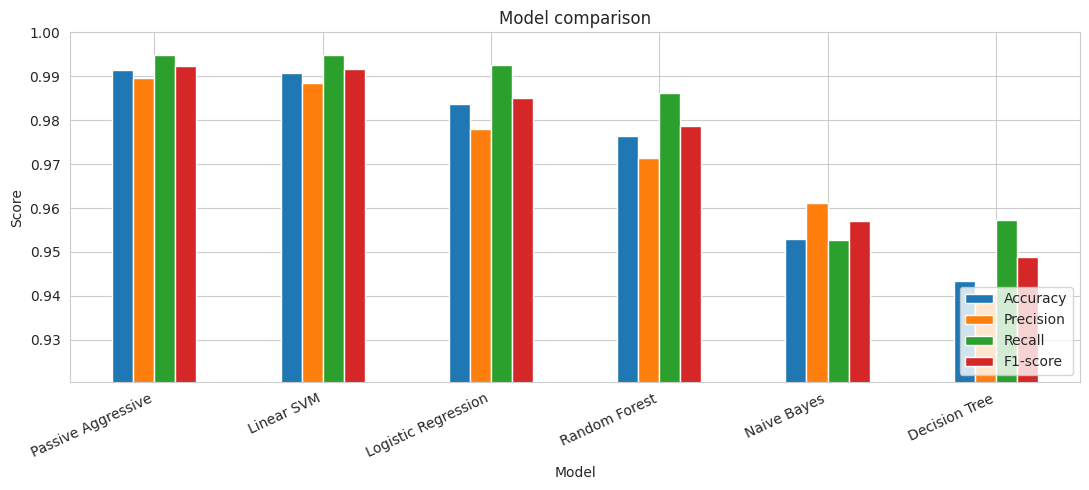

In [7]:
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]]
plot_df.plot(kind="bar", figsize=(11, 5), ylim=(plot_df.values.min() - 0.02, 1.0))
plt.title("Model comparison"); plt.ylabel("Score"); plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 8. Detailed evaluation of the best model

Best model: Passive Aggressive
              precision    recall  f1-score   support

        FAKE       0.99      0.99      0.99      3493
        REAL       0.99      0.99      0.99      4239

    accuracy                           0.99      7732
   macro avg       0.99      0.99      0.99      7732
weighted avg       0.99      0.99      0.99      7732



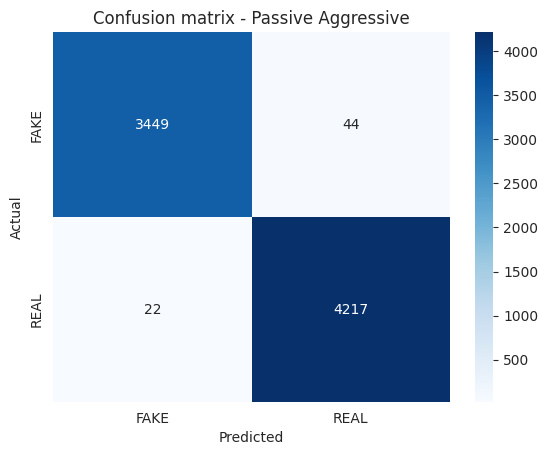

In [8]:
best_name = results_df.loc[0, "Model"]
best_model = trained[best_name]
print("Best model:", best_name)
print(classification_report(y_test, preds[best_name], target_names=["FAKE", "REAL"]))

cm = confusion_matrix(y_test, preds[best_name])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["FAKE", "REAL"], yticklabels=["FAKE", "REAL"])
plt.title(f"Confusion matrix - {best_name}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

## 9. Which words influence the decision? (Logistic Regression)

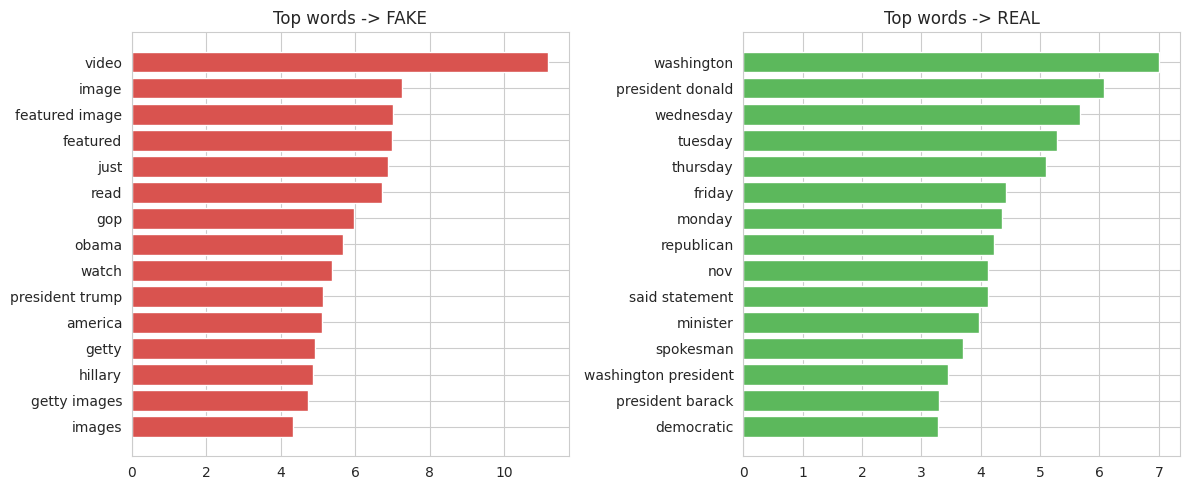

In [9]:
lr = trained["Logistic Regression"]
words = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top_fake = words[order[:15]]
top_real = words[order[-15:]][::-1]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(top_fake[::-1], np.sort(lr.coef_[0])[:15][::-1] * -1, color="#d9534f"); ax[0].set_title("Top words -> FAKE")
ax[1].barh(top_real[::-1], np.sort(lr.coef_[0])[-15:], color="#5cb85c"); ax[1].set_title("Top words -> REAL")
plt.tight_layout(); plt.show()

## 10. Save the best model and test with custom news

In [10]:
joblib.dump(best_model, "fake_news_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Saved:", best_name)

def predict_news(text):
    vec = tfidf.transform([clean_text(text)])
    label = best_model.predict(vec)[0]
    return "REAL" if label == 1 else "FAKE"

samples = [
    "The central bank announced on Tuesday that interest rates will remain unchanged after a two day policy meeting.",
    "SHOCKING!!! Secret document PROVES celebrities are controlled by aliens, the media is hiding the truth from you!",
]
for s in samples:
    print(predict_news(s), "<-", s[:80], "...")

Saved: Passive Aggressive
REAL <- The central bank announced on Tuesday that interest rates will remain unchanged  ...
FAKE <- SHOCKING!!! Secret document PROVES celebrities are controlled by aliens, the med ...


In [11]:
# Try your own news text
user_text = input("Paste a news article / headline: ")
print("Prediction:", predict_news(user_text))

Paste a news article / headline: In August 1835, the New York Sun published a series of articles claiming that astronomers had discovered life on the Moon
Prediction: FAKE


## 11. Interactive dashboard
This section turns the trained models into a small web dashboard using **Gradio** (runs inside Colab, no extra setup).

**Tabs:** Check an article - Model comparison - Confusion matrix - Data insights.

Run the next two cells, then the launch cell at the end of this section. Colab shows the dashboard below the cell and also prints a public link (valid for about 72 hours) that you can open in a separate browser tab during your demo.

In [12]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
import gradio as gr
print("Gradio", gr.__version__)

Gradio 6.29.0


In [13]:
# ---------- Dashboard helper functions (plain Python, used by the Gradio UI) ----------
FAKE_C, REAL_C = "#eb6834", "#2a78d6"            # orange = FAKE, blue = REAL (colourblind-safe pair)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e3e2de", "#fcfcfb"

def _new_fig(w=7.5, h=4.2):
    fig, ax = plt.subplots(figsize=(w, h), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.grid(False)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(MUTED); ax.yaxis.label.set_color(MUTED)
    ax.title.set_color(INK)
    return fig, ax

def _confidence(model, vec):
    # Probability of REAL. Models without predict_proba (SVM, Passive Aggressive) use a
    # sigmoid of the decision score, so treat that number as a rough confidence only.
    if hasattr(model, "predict_proba"):
        return float(model.predict_proba(vec)[0][1]), True
    return float(1 / (1 + np.exp(-model.decision_function(vec)[0]))), False

def explain_plot(vec, k=8):
    # Words that pushed the decision, from the Logistic Regression weights.
    contrib = vec.multiply(lr.coef_[0]).tocoo()
    if contrib.nnz == 0:
        return None
    pairs = sorted(zip(contrib.col, contrib.data), key=lambda p: -abs(p[1]))[:k][::-1]
    names = [words[i] for i, _ in pairs]
    vals = [v for _, v in pairs]
    fig, ax = _new_fig(7.5, 0.45 * len(pairs) + 1.4)
    ax.barh(names, vals, color=[REAL_C if v > 0 else FAKE_C for v in vals], height=0.6)
    ax.axvline(0, color=GRID, lw=1)
    ax.set_title("Words that drove the decision  (orange -> FAKE, blue -> REAL)", fontsize=10, loc="left")
    ax.set_xlabel("Contribution (Logistic Regression)")
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    fig.tight_layout(); plt.close(fig)
    return fig

def analyse(text, model_name):
    cleaned = clean_text(text or "")
    if len(cleaned.split()) < 5:
        return None, "Please paste at least a full headline or a few sentences (5+ words).", None
    vec = tfidf.transform([cleaned])
    model = trained[model_name]
    p_real, calibrated = _confidence(model, vec)
    verdict = "REAL" if model.predict(vec)[0] == 1 else "FAKE"
    note = f"**Verdict: {verdict}**  (model: {model_name})"
    if not calibrated:
        note += "\n\n*This model has no true probabilities, so the percentage is only a rough confidence.*"
    note += "\n\n*The model judges writing style learned from this dataset. It does not fact-check anything.*"
    return {"REAL": p_real, "FAKE": 1 - p_real}, note, explain_plot(vec)

METRICS = ["F1-score", "Accuracy", "Precision", "Recall", "Train time (s)"]

def compare_plot(metric):
    d = results_df.sort_values(metric, ascending=(metric == "Train time (s)"))
    fig, ax = _new_fig(7.5, 4.0)
    ax.barh(d["Model"][::-1], d[metric][::-1], color=REAL_C, height=0.6)
    for y, v in enumerate(d[metric][::-1]):
        ax.text(v, y, f"  {v:.4f}" if metric != "Train time (s)" else f"  {v:.2f}s", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, d[metric].max() * 1.15)   # bars always start at zero; the labels carry the exact values
    ax.set_title(f"{metric} by model" + ("  (lower is better)" if metric == "Train time (s)" else ""), fontsize=10, loc="left")
    ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
    fig.tight_layout(); plt.close(fig)
    return fig

def confusion_plot(model_name):
    cm = confusion_matrix(y_test, preds[model_name])
    fig, ax = _new_fig(4.8, 4.2)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["FAKE", "REAL"]); ax.set_yticks([0, 1], ["FAKE", "REAL"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    acc = accuracy_score(y_test, preds[model_name])
    ax.set_title(f"{model_name}  -  accuracy {acc:.2%}", fontsize=10, loc="left")
    for s in ax.spines.values():
        s.set_visible(False)
    fig.tight_layout(); plt.close(fig)
    return fig

INSIGHTS = ["Class balance", "Article length", "Top words"]

def insight_plot(view):
    if view == "Class balance":
        counts = df["label"].value_counts().sort_index()
        fig, ax = _new_fig(5.5, 3.8)
        bars = ax.bar(["FAKE", "REAL"], counts.values, color=[FAKE_C, REAL_C], width=0.55)
        for b, v in zip(bars, counts.values):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=10, color=INK)
        ax.set_title("Articles per class", fontsize=10, loc="left"); ax.set_ylim(0, counts.max() * 1.12)
    elif view == "Article length":
        fig, ax = _new_fig(7.5, 3.8)
        for lab, col, name in ((0, FAKE_C, "FAKE"), (1, REAL_C, "REAL")):
            ax.hist(df.loc[df.label == lab, "text_len"].clip(upper=2000), bins=40, alpha=0.65,
                    color=col, label=name, edgecolor=SURFACE, linewidth=0.8)
        ax.set_title("Article length in words (clipped at 2000)", fontsize=10, loc="left")
        ax.set_xlabel("Words"); ax.legend(frameon=False, labelcolor=MUTED)
    else:
        order = np.argsort(lr.coef_[0])
        fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), facecolor=SURFACE)
        for ax, idx, col, title in ((axes[0], order[:12][::-1], FAKE_C, "Top words -> FAKE"),
                                    (axes[1], order[-12:], REAL_C, "Top words -> REAL")):
            ax.set_facecolor(SURFACE); ax.grid(False)
            ax.barh(words[idx], np.abs(lr.coef_[0][idx]), color=col, height=0.6)
            ax.set_title(title, fontsize=10, loc="left", color=INK)
            ax.tick_params(colors=MUTED, labelsize=9)
            ax.grid(axis="x", color=GRID, lw=0.6); ax.set_axisbelow(True)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)
            for s in ("left", "bottom"):
                ax.spines[s].set_color(GRID)
        ax = axes[0]
    if view != "Top words":
        ax.grid(axis="y" if view == "Class balance" else "both", color=GRID, lw=0.6); ax.set_axisbelow(True)
    fig.tight_layout(); plt.close(fig)
    return fig

best_row = results_df.iloc[0]
header_md = (
    f"# Fake News Detection Dashboard\n"
    f"**{len(df):,}** articles  |  **{len(trained)}** models  |  best model: **{best_row['Model']}**  |  "
    f"accuracy **{best_row['Accuracy']:.2%}**  |  F1 **{best_row['F1-score']:.4f}**"
)
print("Dashboard functions ready.")

Dashboard functions ready.


In [14]:
# ---------- Build and launch the dashboard ----------
examples = [
    ["The central bank announced on Tuesday that interest rates will remain unchanged after a two day policy meeting.", best_name],
    ["SHOCKING!!! Secret document PROVES celebrities are controlled by aliens, the media is hiding the truth from you!", best_name],
]
show_table = results_df.round({"Accuracy": 4, "Precision": 4, "Recall": 4, "F1-score": 4})

with gr.Blocks(title="Fake News Detection Dashboard") as demo:
    gr.Markdown(header_md)
    with gr.Tabs():
        with gr.Tab("Check an article"):
            with gr.Row():
                with gr.Column(scale=2):
                    inp = gr.Textbox(lines=8, label="Paste a news headline or article")
                    mdl = gr.Dropdown(list(trained), value=best_name, label="Model")
                    btn = gr.Button("Analyse", variant="primary")
                with gr.Column(scale=1):
                    out_label = gr.Label(label="Prediction", num_top_classes=2)
                    out_note = gr.Markdown()
            out_plot = gr.Plot(label="Explanation")
            btn.click(analyse, [inp, mdl], [out_label, out_note, out_plot])
            gr.Examples(examples=examples, inputs=[inp, mdl], cache_examples=False)

        with gr.Tab("Model comparison"):
            metric = gr.Dropdown(METRICS, value="F1-score", label="Metric")
            cmp_plot = gr.Plot()
            gr.Dataframe(value=show_table, label="All results", interactive=False)
            metric.change(compare_plot, metric, cmp_plot)

        with gr.Tab("Confusion matrix"):
            cm_model = gr.Dropdown(list(trained), value=best_name, label="Model")
            cm_plot = gr.Plot()
            cm_model.change(confusion_plot, cm_model, cm_plot)

        with gr.Tab("Data insights"):
            view = gr.Radio(INSIGHTS, value="Class balance", label="View")
            ins_plot = gr.Plot()
            view.change(insight_plot, view, ins_plot)

    demo.load(compare_plot, metric, cmp_plot)
    demo.load(confusion_plot, cm_model, cm_plot)
    demo.load(insight_plot, view, ins_plot)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ff2044a7135d6e7e23.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Conclusion
- TF-IDF with linear models (Logistic Regression, SVM, Passive Aggressive) gives very high accuracy and trains in seconds.
- Naive Bayes is the fastest but slightly less accurate; Decision Tree is interpretable but weaker; Random Forest is accurate but slower.
- The best model is saved with `joblib` so it can be reused without retraining.

**Limitations:** The dataset is mostly US political news from one period, so the model may not generalise to other topics or newer articles. It learns *writing style*, not factual truth.

**Future scope:** Deep learning (LSTM/BERT), a Streamlit/Flask web app, fact-checking with external sources, multilingual (e.g. Hindi) detection.